In [18]:
print(open("../src/db.py").read())
print("-----")
print(open("../src/features.py").read()[:100])

import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv()

def get_engine():
    return create_engine(URL.create(
        "postgresql+psycopg2",
        username=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
        host=os.getenv("DB_HOST", "localhost"), port=int(os.getenv("DB_PORT", 5432)),
        database=os.getenv("DB_NAME")))

-----
import pandas as pd

ADDONS = ["online_security", "online_backup", "device_protection",
          "t


In [21]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from src.db import get_engine
from src.features import build_model_df, encode, TARGET

raw = pd.read_sql("SELECT * FROM customers", get_engine())
model_df = build_model_df(raw)
X = model_df.drop(columns=TARGET)
y = model_df[TARGET]

gbm = joblib.load("../models/churn_lgbm.pkl")
cols = joblib.load("../models/encoded_columns.pkl")
X_enc = encode(X, cols)

scores = pd.DataFrame({"customer_id": raw["customer_id"],
                       "churn_prob": gbm.predict_proba(X_enc)[:, 1]})
scores.shape

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


(7043, 2)

## KAPLAN MEIER (how long do customers last)

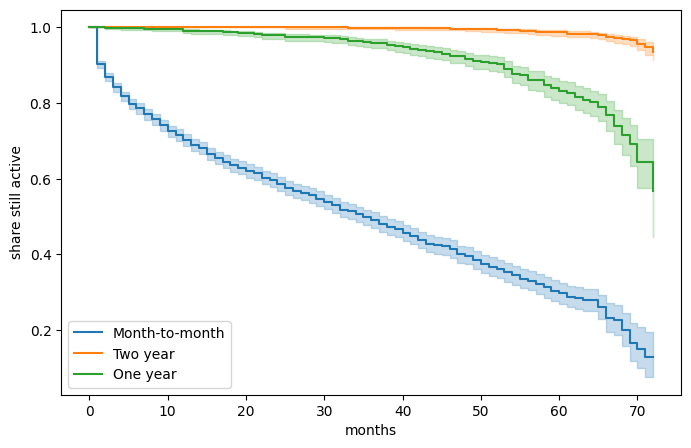

In [22]:
from lifelines import KaplanMeierFitter

duration = model_df["tenure_months"].clip(lower=1)   # the 11 zero-tenure customers count as 1 month
event = model_df[TARGET]                             # 1 = churned, 0 = still active (censored)

fig, ax = plt.subplots(figsize=(8, 5))
for c in model_df["contract"].unique():
    m = model_df["contract"] == c
    KaplanMeierFitter().fit(duration[m], event[m], label=c).plot_survival_function(ax=ax)
ax.set_xlabel("months"); ax.set_ylabel("share still active")
plt.savefig("../reports/figures/km_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

## cox model 

In [23]:
from lifelines import CoxPHFitter

drop_cols = ["tenure_months", "total_charges", "n_services", "has_autopay",
             "internet_service_No", "payment_method_Mailed check"]
cox_X = encode(X).drop(columns=drop_cols)
cox_X["monthly_charges"] = (cox_X["monthly_charges"] - cox_X["monthly_charges"].mean()) / cox_X["monthly_charges"].std()

cph = CoxPHFitter(penalizer=0.01)
cph.fit(cox_X.assign(duration=duration, event=event), duration_col="duration", event_col="event")
display(cph.summary[["exp(coef)", "p"]].sort_values("exp(coef)"))

# expected months (out of the next 12) each customer stays, given they've lasted this long
times = np.arange(1, 85)
S = cph.predict_survival_function(cox_X, times=times).to_numpy()   # rows = months, columns = customers
t0 = duration.to_numpy(); i = np.arange(len(t0))
exp_months = np.zeros(len(t0))
for k in range(1, 13):
    exp_months += S[np.clip(t0 + k - 1, 0, 83), i] / S[np.clip(t0 - 1, 0, 83), i]
scores["exp_months_12"] = exp_months
scores.to_csv("../data/customer_scores.csv", index=False)
scores["exp_months_12"].describe()

,exp(coef),p
covariate,,
contract,0.227248,2.510041e-155
dependents,0.379190,2.725828e-25
payment_method_Credit card (automatic),0.541857,4.783240e-13
online_backup,0.549278,4.293161e-27
online_security,0.573625,4.168719e-17
payment_method_Bank transfer (automatic),0.574282,1.933199e-11
partner,0.668722,1.507826e-15
tech_support,0.703909,7.489586e-08
device_protection,0.736495,4.339623e-08


count    7043.000000
mean       10.841434
std         1.307871
min         1.057795
25%        10.284015
50%        11.310318
75%        11.823660
max        12.000000
Name: exp_months_12, dtype: float64

In [24]:
check = pd.DataFrame({"exp_months": scores["exp_months_12"], "churned": y.to_numpy()})
display(check.groupby(pd.qcut(check["exp_months"], 5, duplicates="drop"), observed=True)["churned"].agg(["mean", "count"]))
display(scores.groupby(X["contract"].to_numpy())["exp_months_12"].mean())

,mean,count
exp_months,,
"(1.0570000000000002, 9.963]",0.576295,1409
"(9.963, 10.916]",0.404830,1408
"(10.916, 11.584]",0.224273,1409
"(11.584, 11.877]",0.099432,1408
"(11.877, 12.0]",0.022001,1409


Month-to-month    10.184800
One year          11.401273
Two year          11.856074
Name: exp_months_12, dtype: float64

In [25]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
n = len(model_df)
treat = rng.integers(0, 2, n)        # 1 = got the offer, assigned by coin flip (like a real A/B test)

# PLANTED TRUTH (synthetic): who actually responds to an offer
movable = ((X["contract"] == "Month-to-month") & (X["internet_service"] != "Fiber optic")).to_numpy()
stuck = ((X["internet_service"] == "Fiber optic") & (X["payment_method"] == "Electronic check")).to_numpy()
p_save = np.where(movable, 0.50, np.where(stuck, 0.0, 0.10))   # chance the offer saves a would-be churner

saved = (treat == 1) & (y.to_numpy() == 1) & (rng.random(n) < p_save)
y_obs = np.where(saved, 0, y.to_numpy())          # outcome after the "campaign"

# T-learner: one model for treated customers, one for control, then subtract
idx_tr, _ = train_test_split(np.arange(n), test_size=0.3, stratify=treat, random_state=42)
is_tr = np.zeros(n, bool); is_tr[idx_tr] = True
te = ~is_tr
params = dict(n_estimators=150, learning_rate=0.05, num_leaves=8,
              min_child_samples=40, random_state=42, verbose=-1)
m_t = lgb.LGBMClassifier(**params).fit(X_enc[is_tr & (treat == 1)], y_obs[is_tr & (treat == 1)])
m_c = lgb.LGBMClassifier(**params).fit(X_enc[is_tr & (treat == 0)], y_obs[is_tr & (treat == 0)])
uplift = m_c.predict_proba(X_enc)[:, 1] - m_t.predict_proba(X_enc)[:, 1]   # fall in churn probability caused by the offer
scores["uplift"] = uplift

# evaluate on customers the uplift models never saw
ev = pd.DataFrame({"uplift": uplift[te], "risk": scores["churn_prob"].to_numpy()[te],
                   "treat": treat[te], "y": y_obs[te]})

def real_effect(d):      # churn rate without the offer minus churn rate with it
    return d.loc[d.treat == 0, "y"].mean() - d.loc[d.treat == 1, "y"].mean()

ev["bucket"] = pd.qcut(ev["uplift"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
rows = []
for b, d in ev.groupby("bucket", observed=True):
    rows.append({"bucket (5 = highest predicted uplift)": b, "customers": len(d),
                 "churn without offer": d.loc[d.treat == 0, "y"].mean(),
                 "churn with offer": d.loc[d.treat == 1, "y"].mean()})
tab = pd.DataFrame(rows)
tab["real effect"] = tab["churn without offer"] - tab["churn with offer"]
display(tab.round(3))

k = int(0.2 * len(ev))
for name in ["uplift", "risk"]:
    print(f"target top 20% by {name:6s}: real effect of the offer = {real_effect(ev.nlargest(k, name)):.3f}")

scores.to_csv("../data/customer_scores.csv", index=False)

,bucket (5 = highest predicted uplift),customers,churn without offer,churn with offer,real effect
0,1,423,0.372,0.353,0.019
1,2,422,0.221,0.219,0.002
2,3,423,0.074,0.068,0.006
3,4,422,0.285,0.270,0.015
4,5,423,0.360,0.244,0.117


target top 20% by uplift: real effect of the offer = 0.115
target top 20% by risk  : real effect of the offer = 0.016


In [26]:
from sklearn.model_selection import StratifiedKFold

uplift_oof = np.zeros(n)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for tr_idx, va_idx in skf.split(X_enc, treat):
    tr_t = tr_idx[treat[tr_idx] == 1]
    tr_c = tr_idx[treat[tr_idx] == 0]
    mt = lgb.LGBMClassifier(**params).fit(X_enc.iloc[tr_t], y_obs[tr_t])
    mc = lgb.LGBMClassifier(**params).fit(X_enc.iloc[tr_c], y_obs[tr_c])
    uplift_oof[va_idx] = (mc.predict_proba(X_enc.iloc[va_idx])[:, 1]
                          - mt.predict_proba(X_enc.iloc[va_idx])[:, 1])
scores["uplift"] = uplift_oof

ev_all = pd.DataFrame({"uplift": uplift_oof, "risk": scores["churn_prob"].to_numpy(),
                       "treat": treat, "y": y_obs})
k = int(0.2 * n)
for name in ["uplift", "risk"]:
    d = ev_all.nlargest(k, name)
    print(f"top 20% by {name:6s}: real effect =",
          round(d.loc[d.treat == 0, "y"].mean() - d.loc[d.treat == 1, "y"].mean(), 3))
print("average predicted uplift, top 20%:",
      round(ev_all.nlargest(k, "uplift")["uplift"].mean(), 3))

top 20% by uplift: real effect = 0.109
top 20% by risk  : real effect = 0.053
average predicted uplift, top 20%: 0.195


In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

MARGIN = 0.30        # assumption: 30% of revenue is profit. State this in the README
scores["monthly_charges"] = model_df["monthly_charges"].to_numpy()
scores["contract"] = X["contract"].to_numpy()
scores["clv_12m"] = scores["monthly_charges"] * MARGIN * scores["exp_months_12"]
print("correlation with IBM's CLTV:", round(scores["clv_12m"].corr(raw["cltv"]), 3))
print("share of customers with negative uplift (offer backfires):", round((scores["uplift"] < 0).mean(), 3))

Z = StandardScaler().fit_transform(scores[["churn_prob", "clv_12m", "uplift"]])
for k in range(3, 7):
    print("k =", k, "silhouette =", round(silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z)), 3))

K = 4
scores["cluster"] = KMeans(K, n_init=10, random_state=42).fit_predict(Z)
profile = scores.groupby("cluster").agg(
    customers=("customer_id", "count"), churn_prob=("churn_prob", "mean"),
    clv_12m=("clv_12m", "mean"), uplift=("uplift", "mean")).round(3)
display(profile)

scores.to_csv("../data/customer_scores.csv", index=False)

correlation with IBM's CLTV: 0.111
share of customers with negative uplift (offer backfires): 0.364
k = 3 silhouette = 0.392
k = 4 silhouette = 0.449
k = 5 silhouette = 0.422
k = 6 silhouette = 0.397


,customers,churn_prob,clv_12m,uplift
cluster,,,,
0,900,0.458,171.697,0.241
1,2266,0.095,100.988,0.025
2,2752,0.132,293.987,-0.015
3,1125,0.773,245.585,-0.008


In [28]:
prof = scores.groupby("cluster")[["churn_prob", "clv_12m", "uplift"]].mean()
display(prof.round(3))

names = {}
names[prof["uplift"].idxmax()] = "Persuadables"
rest = prof.drop(index=list(names))
names[rest["churn_prob"].idxmax()] = "High risk, unresponsive"
rest = prof.drop(index=list(names))
names[rest["clv_12m"].idxmax()] = "Loyal, high value"
rest = prof.drop(index=list(names))
names[rest.index[0]] = "Low value, low risk"

scores["segment"] = scores["cluster"].map(names)
scores.to_csv("../data/customer_scores.csv", index=False)
scores["segment"].value_counts()

,churn_prob,clv_12m,uplift
cluster,,,
0,0.458,171.697,0.241
1,0.095,100.988,0.025
2,0.132,293.987,-0.015
3,0.773,245.585,-0.008


segment
Loyal, high value          2752
Low value, low risk        2266
High risk, unresponsive    1125
Persuadables                900
Name: count, dtype: int64

In [30]:
top = scores["uplift"].nlargest(int(0.2 * n)).index.to_numpy()
real_top = y_obs[top][treat[top] == 0].mean() - y_obs[top][treat[top] == 1].mean()
pred_top = scores["uplift"].to_numpy()[top].mean()
factor = real_top / pred_top
print("real:", round(real_top, 3), "| predicted:", round(pred_top, 3), "| factor:", round(factor, 3))

scores["uplift_cal"] = scores["uplift"] * factor
scores.to_csv("../data/customer_scores.csv", index=False)

real: 0.109 | predicted: 0.195 | factor: 0.559


In [29]:
scores.columns.tolist()

['customer_id',
 'churn_prob',
 'exp_months_12',
 'uplift',
 'monthly_charges',
 'contract',
 'clv_12m',
 'cluster',
 'segment']

In [31]:
pd.read_csv("../data/customer_scores.csv").columns.tolist()

['customer_id',
 'churn_prob',
 'exp_months_12',
 'uplift',
 'monthly_charges',
 'contract',
 'clv_12m',
 'cluster',
 'segment',
 'uplift_cal']

In [32]:
ev_all = pd.DataFrame({"u": scores["uplift_cal"].to_numpy(), "treat": treat, "y": y_obs})
rows = []
for s in [0.05, 0.10, 0.20, 0.40]:
    d = ev_all.nlargest(int(s * n), "u")
    real = d.loc[d.treat == 0, "y"].mean() - d.loc[d.treat == 1, "y"].mean()
    rows.append({"share": s, "customers": len(d),
                 "predicted (calibrated)": d["u"].mean(), "real effect": real})
pd.DataFrame(rows).round(3)

,share,customers,predicted (calibrated),real effect
0,0.05,352,0.189,0.226
1,0.10,704,0.151,0.194
2,0.20,1408,0.109,0.109
3,0.40,2817,0.068,0.065


In [34]:
chk = pd.read_csv("../data/customer_scores.csv")
print(chk.shape)
print(chk.columns.tolist())
print(chk["segment"].value_counts())
print(chk.groupby("segment")[["churn_prob", "clv_12m", "uplift"]].mean().round(3))

(7043, 10)
['customer_id', 'churn_prob', 'exp_months_12', 'uplift', 'monthly_charges', 'contract', 'clv_12m', 'cluster', 'segment', 'uplift_cal']
segment
Loyal, high value          2752
Low value, low risk        2266
High risk, unresponsive    1125
Persuadables                900
Name: count, dtype: int64
                         churn_prob  clv_12m  uplift
segment                                             
High risk, unresponsive       0.773  245.585  -0.008
Low value, low risk           0.095  100.988   0.025
Loyal, high value             0.132  293.987  -0.015
Persuadables                  0.458  171.697   0.241
